# Анализ открытых тестов: строительство газопровода

Ноутбук исследует **все предоставленные открытые тесты**. Основной вопрос: какие длины труб приходят в каждом сценарии и что это означает для выбора стратегии размещения?

Здесь есть:

1. Проверка формата и корректности последовательностей PID.
2. Сводка по всем тестам и распределения длин **по каждому тесту отдельно**.
3. Сравнение тестов без доминирования самого большого сценария.
4. Изменение поступлений и удалений во времени.
5. Число и суммарная длина одновременно активных труб; верхняя граница достижимого KPI.
6. Удаления по длинам, время жизни труб и подробный разбор выбранного теста.
7. Выводы для дальнейших экспериментов с алгоритмами.

**Граница анализа:** это статистика открытых входных данных, а не результаты запуска алгоритмов. Размеры свободных промежутков и фрагментация зависят от конкретной стратегии размещения и здесь не моделируются. Распределение закрытых тестов неизвестно.

Все выводы и графики пересчитываются при **Run All / Выполнить все**. Исходные данные не изменяются. Зависимости: Python 3.10+, NumPy, pandas, Matplotlib и IPython; для работы в Jupyter также нужен ipykernel.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import math
import platform
import re
import zipfile

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import Markdown, display

%matplotlib inline

# При необходимости установите зависимости отдельной ячейкой:
# %pip install numpy pandas matplotlib ipython ipykernel

# None: искать данные в текущей папке и родительских папках.
# Если ноутбук открыт из другого места, задайте Path("путь/к/папке/с/2.zip").
DATA_ROOT = None

# Какой сценарий подробно разобрать в разделе 7. Можно изменить на 1..15.
DETAIL_TEST = 14
TIME_BINS = 20

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "figure.dpi": 115,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 45)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}".replace(",", " "))

BLUE, ORANGE, GREEN = "#2979b9", "#e88b32", "#259b79"
print("Версии:", {"Python": platform.python_version(), "NumPy": np.__version__,
                  "pandas": pd.__version__, "Matplotlib": matplotlib.__version__})
print("Расчёт (UTC):", datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"))

Версии: {'Python': '3.13.5', 'NumPy': '2.1.3', 'pandas': '2.2.3', 'Matplotlib': '3.10.0'}
Расчёт (UTC): 2026-10-16 13:58:56


## 1. Загрузка и проверка данных

В файле теста первые два числа — вес и количество рабочих команд `n`. Затем идут `n` команд и завершающий `0`. Положительное число задаёт длину очередной трубы, отрицательное — PID удаляемой трубы. **PID увеличивается только при укладке.**

`load_test_files(root)` читает файлы непосредственно из `2.zip`; если архива нет, использует `case2_materials/tests` или `tests`. Возвращает байты файлов и описание источника. Распаковка не нужна.

`analyze_test(test_id, raw)` проверяет формат и допустимость удалений, затем возвращает три объекта:

- сводную строку по сценарию;
- таблицу труб: PID, длина, момент поступления, момент удаления и наблюдавшееся время жизни;
- таблицу событий: команда, длина затронутой трубы и текущая активная нагрузка.

Например, команда `-2` должна удалять ранее поступившую и ещё не удалённую трубу с PID 2. Повторное удаление считается ошибкой. Позиции труб не восстанавливаются: во входных файлах их нет.

In [2]:
def load_test_files(root=None):
    if root is not None:
        roots = [Path(root).expanduser().resolve()]
    else:
        cwd = Path.cwd().resolve()
        roots = [cwd, *cwd.parents]

    for candidate in roots:
        archive = candidate / "2.zip"
        if archive.is_file():
            with zipfile.ZipFile(archive) as z:
                names = [name for name in z.namelist()
                         if re.fullmatch(r"tests/\d+\.in", name)]
                if names:
                    tests = {int(Path(name).stem): z.read(name) for name in names}
                    if len(tests) != len(names):
                        raise ValueError("В архиве повторяются номера тестов")
                    return dict(sorted(tests.items())), str(archive)
        for folder in [candidate / "case2_materials" / "tests", candidate / "tests"]:
            if folder.is_dir():
                files = [p for p in folder.glob("*.in") if p.stem.isdigit()]
                if files:
                    return {int(p.stem): p.read_bytes()
                            for p in sorted(files, key=lambda p: int(p.stem))}, str(folder)
    raise FileNotFoundError("Не найдены 2.zip или папка tests. Укажите DATA_ROOT.")


def longest_run(mask):
    # Длина самой длинной серии подряд идущих True; для пустой серии — 0.
    padded = np.r_[False, np.asarray(mask, dtype=bool), False]
    borders = np.flatnonzero(padded[1:] != padded[:-1])
    return int(np.max(borders[1::2] - borders[::2], initial=0))


def analyze_test(test_id, raw):
    tokens = raw.decode("utf-8-sig").split()
    if len(tokens) < 3:
        raise ValueError(f"Тест {test_id}: отсутствует заголовок или команды")
    weight, n = float(tokens[0]), int(tokens[1])
    commands_with_end = np.array([int(x) for x in tokens[2:]], dtype=np.int64)
    if not math.isfinite(weight) or weight <= 0 or not 1 <= n <= 200_000:
        raise ValueError(f"Тест {test_id}: недопустимый вес или число команд")
    if len(commands_with_end) != n + 1 or commands_with_end[-1] != 0:
        raise ValueError(f"Тест {test_id}: ожидались n команд и завершающий 0")
    commands = commands_with_end[:-1]
    if np.any(commands == 0) or np.any(commands > 40):
        raise ValueError(f"Тест {test_id}: нулевая команда внутри сценария или длина > 40")

    add_count = int(np.count_nonzero(commands > 0))
    if add_count == 0:
        raise ValueError(f"Тест {test_id}: нет поступлений труб")
    lengths = np.zeros(add_count + 1, dtype=np.int64)
    births = np.zeros(add_count + 1, dtype=np.int64)
    deaths = np.full(add_count + 1, -1, dtype=np.int64)
    active = np.zeros(add_count + 1, dtype=bool)
    deltas_m = np.zeros(n, dtype=np.int64)
    event_lengths = np.zeros(n, dtype=np.int64)
    latest_pid = 0

    for index, command in enumerate(commands):
        step = index + 1
        if command > 0:
            latest_pid += 1
            pid = latest_pid
            lengths[pid], births[pid], active[pid] = command, step, True
            deltas_m[index] = command
        else:
            pid = int(-command)
            if pid > latest_pid or not active[pid]:
                raise ValueError(f"Тест {test_id}, шаг {step}: недопустимый PID {pid}")
            active[pid] = False
            deaths[pid] = step
            deltas_m[index] = -lengths[pid]
        event_lengths[index] = lengths[pid]

    is_add = commands > 0
    live_m = np.cumsum(deltas_m)
    live_count = np.cumsum(np.where(is_add, 1, -1))
    peak_m, final_m = int(live_m.max()), int(live_m[-1])
    min_trench = 20 * ((peak_m + 19) // 20)
    hist = np.bincount(lengths[1:], minlength=41)[1:41]
    probabilities = hist[hist > 0] / add_count
    entropy = float(-np.sum(probabilities * np.log2(probabilities)))
    top = sorted(range(1, 41), key=lambda length: (-hist[length - 1], length))[:3]
    top_text = "; ".join(f"{length} м: {100 * hist[length - 1] / add_count:.1f}%"
                         for length in top if hist[length - 1] > 0)
    removed = deaths[1:] >= 0
    observed_steps = np.where(removed, deaths[1:], n + 1) - births[1:]
    total_inserted_m = int(lengths.sum())
    total_removed_m = int(lengths[1:][removed].sum())

    if final_m != total_inserted_m - total_removed_m or np.any(live_m < 0):
        raise ValueError(f"Тест {test_id}: нарушен баланс длин")
    if int(live_count[-1]) != int(active.sum()):
        raise ValueError(f"Тест {test_id}: нарушен баланс числа труб")

    pipes_frame = pd.DataFrame({
        "test": test_id, "pid": np.arange(1, add_count + 1),
        "length": lengths[1:], "birth_step": births[1:],
        "removal_step": np.where(removed, deaths[1:], np.nan),
        "removed": removed, "observed_steps": observed_steps,
        "observed_fraction": observed_steps / n,
    })
    events_frame = pd.DataFrame({
        "test": test_id, "step": np.arange(1, n + 1), "command": commands,
        "is_add": is_add, "pipe_length": event_lengths,
        "live_m": live_m, "live_count": live_count,
    })
    summary_row = {
        "test": test_id, "weight": weight, "commands": n,
        "adds": add_count, "removes": int((~is_add).sum()),
        "removal_event_pct": 100 * float((~is_add).mean()),
        "removed_pipe_pct": 100 * float(removed.mean()),
        "mean_length": float(lengths[1:].mean()),
        "median_length": float(np.median(lengths[1:])),
        "p10_length": float(np.quantile(lengths[1:], .1)),
        "p90_length": float(np.quantile(lengths[1:], .9)),
        "min_length": int(lengths[1:].min()), "max_length": int(lengths[1:].max()),
        "distinct_lengths": int(np.count_nonzero(hist)),
        "small_1_2_pct": 100 * float(hist[:2].sum() / add_count),
        "small_1_5_pct": 100 * float(hist[:5].sum() / add_count),
        "entropy_bits": entropy, "top_lengths": top_text,
        "inserted_m": total_inserted_m, "removed_m": total_removed_m,
        "peak_live_m": peak_m, "final_live_m": final_m,
        "peak_live_pipes": int(live_count.max()),
        "final_live_pipes": int(live_count[-1]),
        "min_trench_m": min_trench,
        "kpi_upper_bound": final_m / min_trench,
        "weighted_upper_bound": weight * final_m / min_trench,
        "inserted_to_peak": total_inserted_m / peak_m,
        "longest_add_run": longest_run(is_add),
        "longest_remove_run": longest_run(~is_add),
    }
    return summary_row, pipes_frame, events_frame


test_files, data_source = load_test_files(DATA_ROOT)
records, pipe_frames, event_frames = [], [], []
for test_id, raw in test_files.items():
    row, pipe_frame, event_frame = analyze_test(test_id, raw)
    records.append(row)
    pipe_frames.append(pipe_frame)
    event_frames.append(event_frame)

summary = pd.DataFrame(records).set_index("test").sort_index()
pipes = pd.concat(pipe_frames, ignore_index=True)
events = pd.concat(event_frames, ignore_index=True)
test_ids = summary.index.tolist()
lengths_axis = np.arange(1, 41)
length_counts = pd.crosstab(pipes["test"], pipes["length"]).reindex(
    index=test_ids, columns=lengths_axis, fill_value=0)
length_percent = length_counts.div(summary["adds"], axis=0) * 100

manifest = pd.DataFrame({
    "Тест": list(test_files),
    "Байт": [len(raw) for raw in test_files.values()],
    "SHA-256": [hashlib.sha256(raw).hexdigest() for raw in test_files.values()],
}).set_index("Тест")
print("Источник:", data_source)
print(f"Проверено тестов: {len(test_ids)}; команд: {len(events):,}; труб: {len(pipes):,}")
print("Формат, диапазоны длин, PID и баланс длин: OK")
display(manifest)

Источник: C:\Users\Rostyan\Desktop\хакатон_сиб\2.zip
Проверено тестов: 15; команд: 280,156; труб: 189,231
Формат, диапазоны длин, PID и баланс длин: OK


,Байт,SHA-256
Тест,,
1,31,5adc57a6e6a775447546abd7b72c3c44429d37f5b34d0e...
2,67,4fb2e25de202250e01a99148d1bc88ac1d338d634c95ff...
3,49,1b0de1bcfab3da1d9fdf97f569b454d7106901afd082a3...
4,76,1303e172ff34edf4a6ed6265247aa1e6de8ca18e73f7ac...
5,35968,bae469c3ed43bba21ab4a9cd9ecef4c53bb2f99fbd9f6c...
6,46,30303402ee57aa1185200d4cd76414d5c649a354250a33...
7,1247,96d010a3353f97e6b35434d7ed4ae7ffdff2378a94dec6...
8,33198,8cca22aa354b6bf9eab4072bfd6b839257d27d061f090d...
9,40456,cfb711efa3a9ccccc17e7170fc7c2ea19c12ed45b789da...


## 2. Сводка сценариев

«Удаления, % команд» и «Удалено, % труб» имеют разные знаменатели: все команды и все поступившие трубы соответственно. Диапазон P10–P90 показывает центральные 80% длин; медиана меньше зависит от редких длинных труб, чем среднее.

Энтропия распределения равна 0 бит, если длина всегда одна и та же, и достигает `log₂(40) ≈ 5,32` бит при равномерном распределении всех 40 длин. Это мера разнообразия длин, **не показатель сложности или случайности всего сценария**.

In [3]:
overview_columns = {
    "weight": "Вес", "commands": "Команд", "adds": "Укладок", "removes": "Удалений",
    "removal_event_pct": "Удаления, % команд", "removed_pipe_pct": "Удалено, % труб",
    "mean_length": "Средняя, м", "median_length": "Медиана, м",
    "p10_length": "P10, м", "p90_length": "P90, м",
    "distinct_lengths": "Разных длин", "small_1_2_pct": "Трубы 1–2 м, %",
    "entropy_bits": "Энтропия, бит",
}
display(summary[list(overview_columns)].rename(columns=overview_columns).round(2))
display(summary[["top_lengths"]].rename(columns={"top_lengths": "Три самых частых длины"}))

,Вес,Команд,Укладок,Удалений,"Удаления, % команд","Удалено, % труб","Средняя, м","Медиана, м","P10, м","P90, м",Разных длин,"Трубы 1–2 м, %","Энтропия, бит"
test,,,,,,,,,,,,,
1,0.100,6,4,2,33.330,50.000,5.750,3.500,1.600,11.700,4,25.000,2.000
2,1.000,18,14,4,22.220,28.570,2.430,2.000,1.000,4.000,5,57.140,2.160
3,1.000,12,8,4,33.330,50.000,3.380,3.500,2.000,4.300,4,25.000,1.910
4,1.000,20,13,7,35.000,53.850,6.000,6.000,5.000,7.800,5,0.000,1.890
5,1.000,7520,5000,2520,33.510,50.400,20.500,20.500,4.900,36.100,40,5.000,5.320
6,1.000,11,8,3,27.270,37.500,3.000,1.500,1.000,5.700,4,62.500,1.750
7,1.000,312,234,78,25.000,33.330,14.000,11.000,1.000,34.000,40,35.900,4.400
8,1.000,6565,3458,3107,47.330,89.850,9.840,10.000,5.000,16.000,33,0.000,2.420
9,1.000,9000,6000,3000,33.330,50.000,10.500,6.000,1.000,32.000,6,33.330,2.580


,Три самых частых длины
test,
1,1 м: 25.0%; 3 м: 25.0%; 4 м: 25.0%
2,1 м: 35.7%; 2 м: 21.4%; 4 м: 21.4%
3,4 м: 37.5%; 2 м: 25.0%; 3 м: 25.0%
4,5 м: 46.2%; 6 м: 30.8%; 7 м: 7.7%
5,1 м: 2.5%; 2 м: 2.5%; 3 м: 2.5%
6,1 м: 50.0%; 3 м: 25.0%; 2 м: 12.5%
7,1 м: 34.2%; 2 м: 1.7%; 3 м: 1.7%
8,5 м: 33.5%; 10 м: 32.9%; 16 м: 19.6%
9,1 м: 16.7%; 2 м: 16.7%; 4 м: 16.7%


## 3. Распределение длин поступающих труб

Каждый столбик — доля труб определённой целой длины **среди поступлений этого теста**. Удаления здесь не учитываются. Пустая позиция означает, что такая длина не встречалась. Оси X одинаковые: от 1 до 40 м. Масштаб Y индивидуален, чтобы видеть форму распределения; для сравнения абсолютных долей используйте следующую тепловую карту.

Оранжевым выделены трубы 1–2 м: они могут заполнять мелкие остатки, которые мы обсуждали. Это аналитическая отметка, а не заранее выбранный штраф для алгоритма.

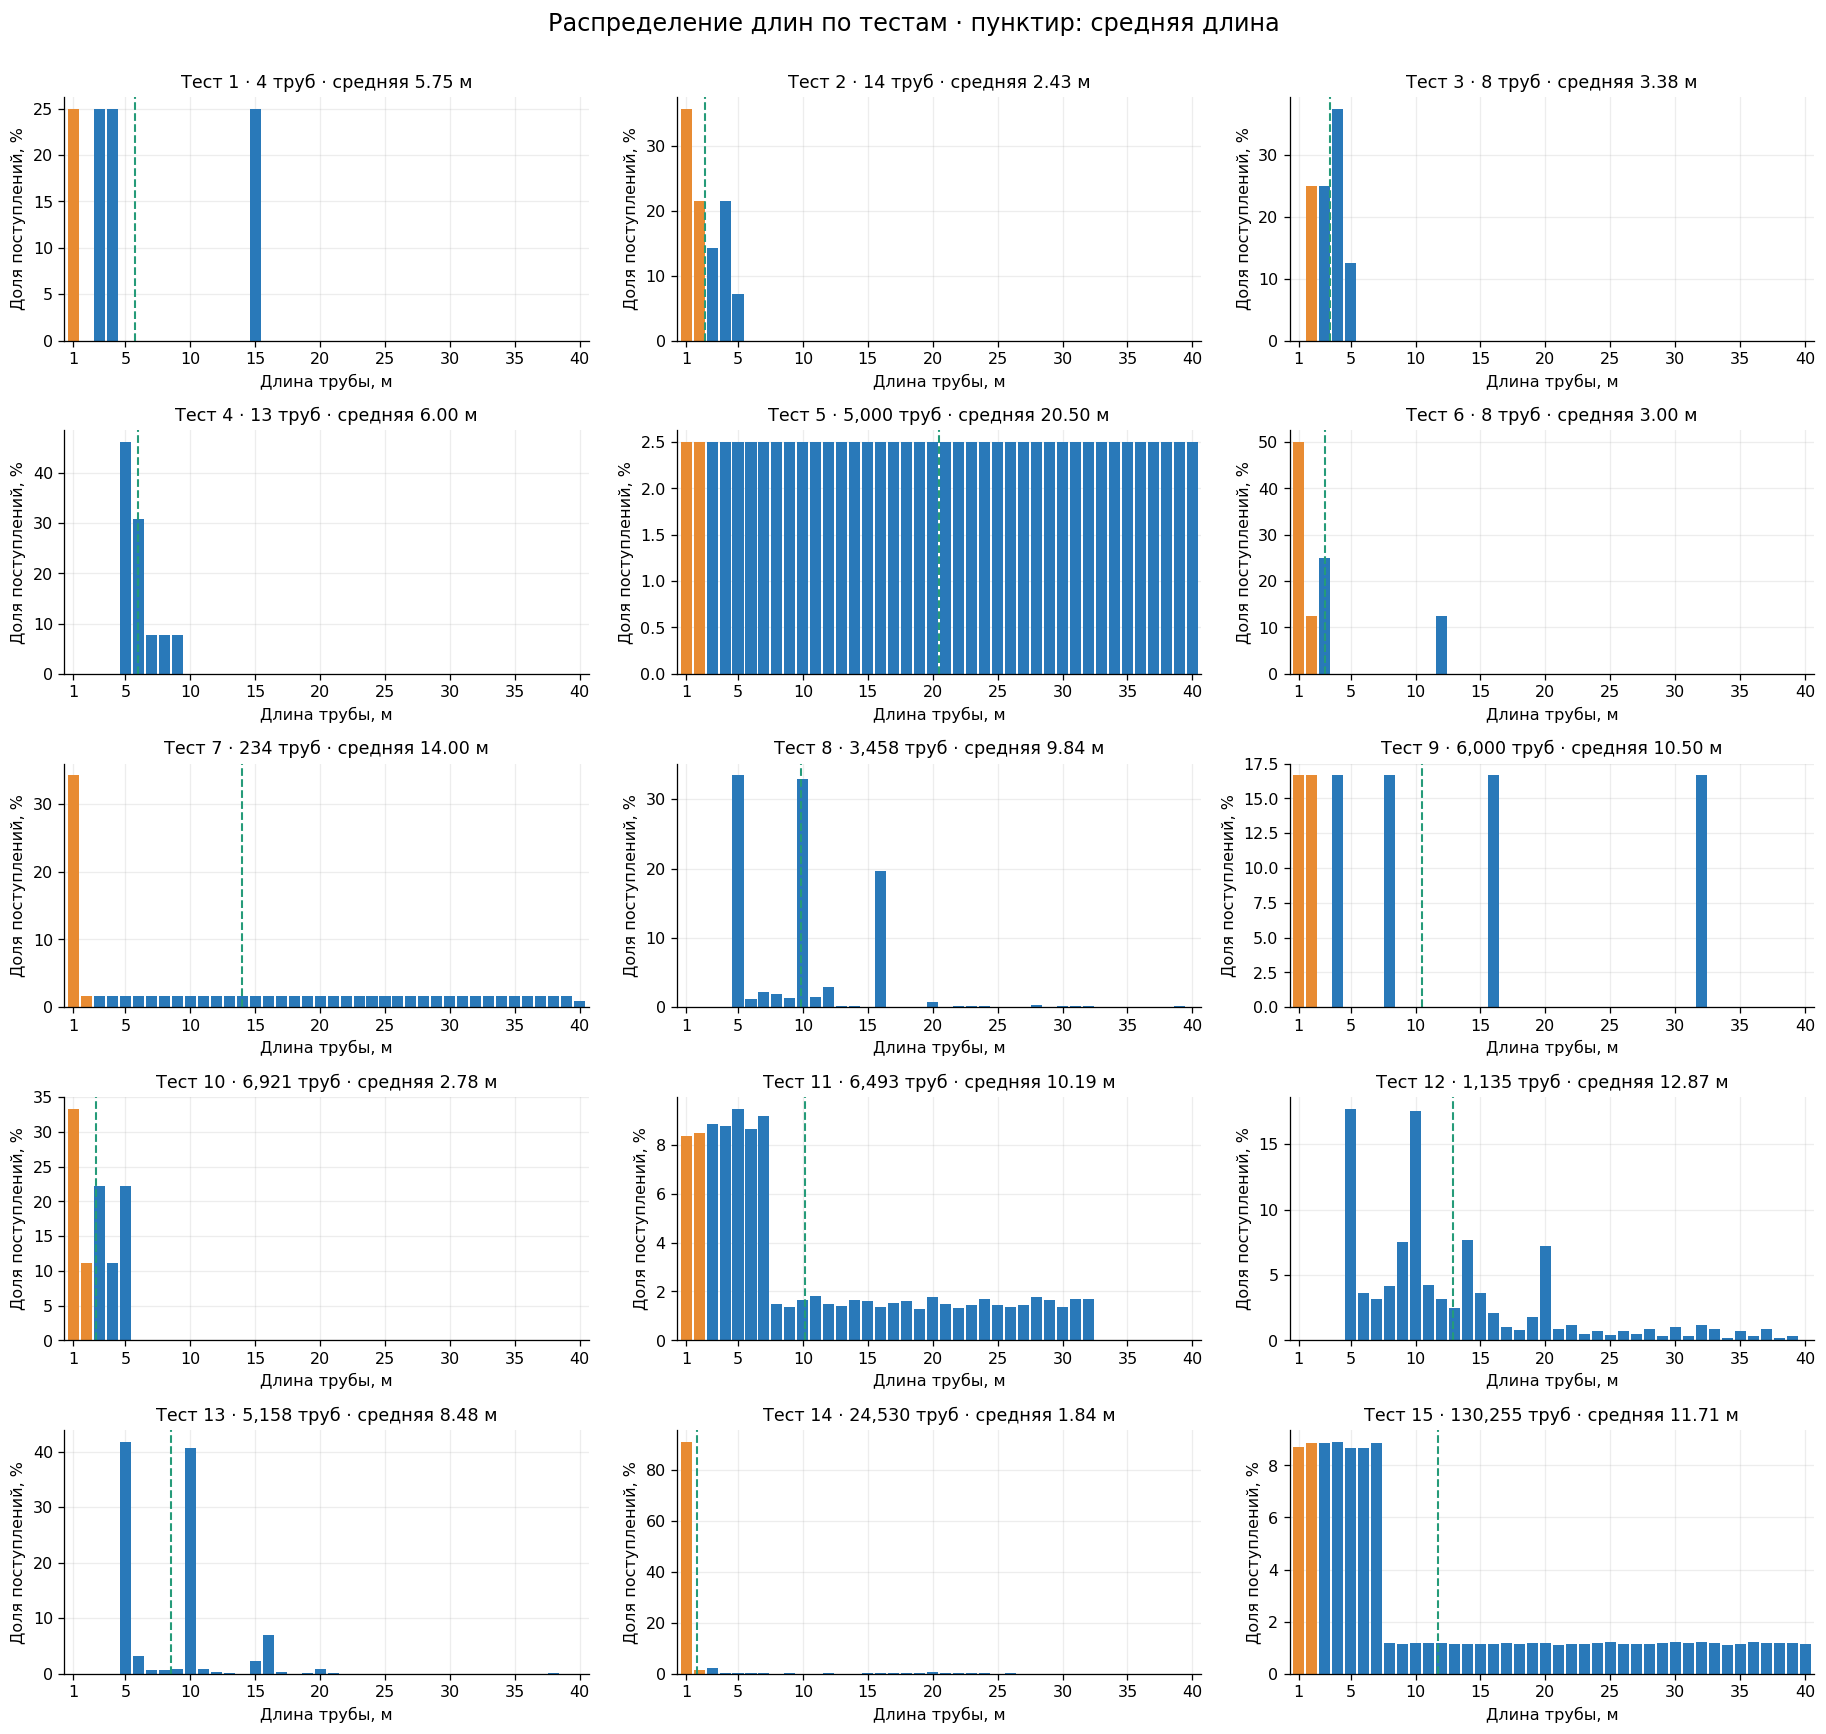

In [4]:
ncols = 3
nrows = math.ceil(len(test_ids) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.0 * nrows), squeeze=False)
for ax, test_id in zip(axes.flat, test_ids):
    percentages = length_percent.loc[test_id].to_numpy()
    colors = [ORANGE if length <= 2 else BLUE for length in lengths_axis]
    ax.bar(lengths_axis, percentages, color=colors, width=.85)
    ax.axvline(summary.at[test_id, "mean_length"], color=GREEN, ls="--", lw=1.3)
    ax.set(title=f"Тест {test_id} · {int(summary.at[test_id, 'adds']):,} труб"
                 f" · средняя {summary.at[test_id, 'mean_length']:.2f} м",
           xlim=(.3, 40.7), xlabel="Длина трубы, м", ylabel="Доля поступлений, %")
    ax.set_xticks([1, 5, 10, 15, 20, 25, 30, 35, 40])
for ax in axes.flat[len(test_ids):]:
    ax.set_visible(False)
fig.suptitle("Распределение длин по тестам · пунктир: средняя длина", fontsize=15, y=1.002)
fig.tight_layout()
plt.show()

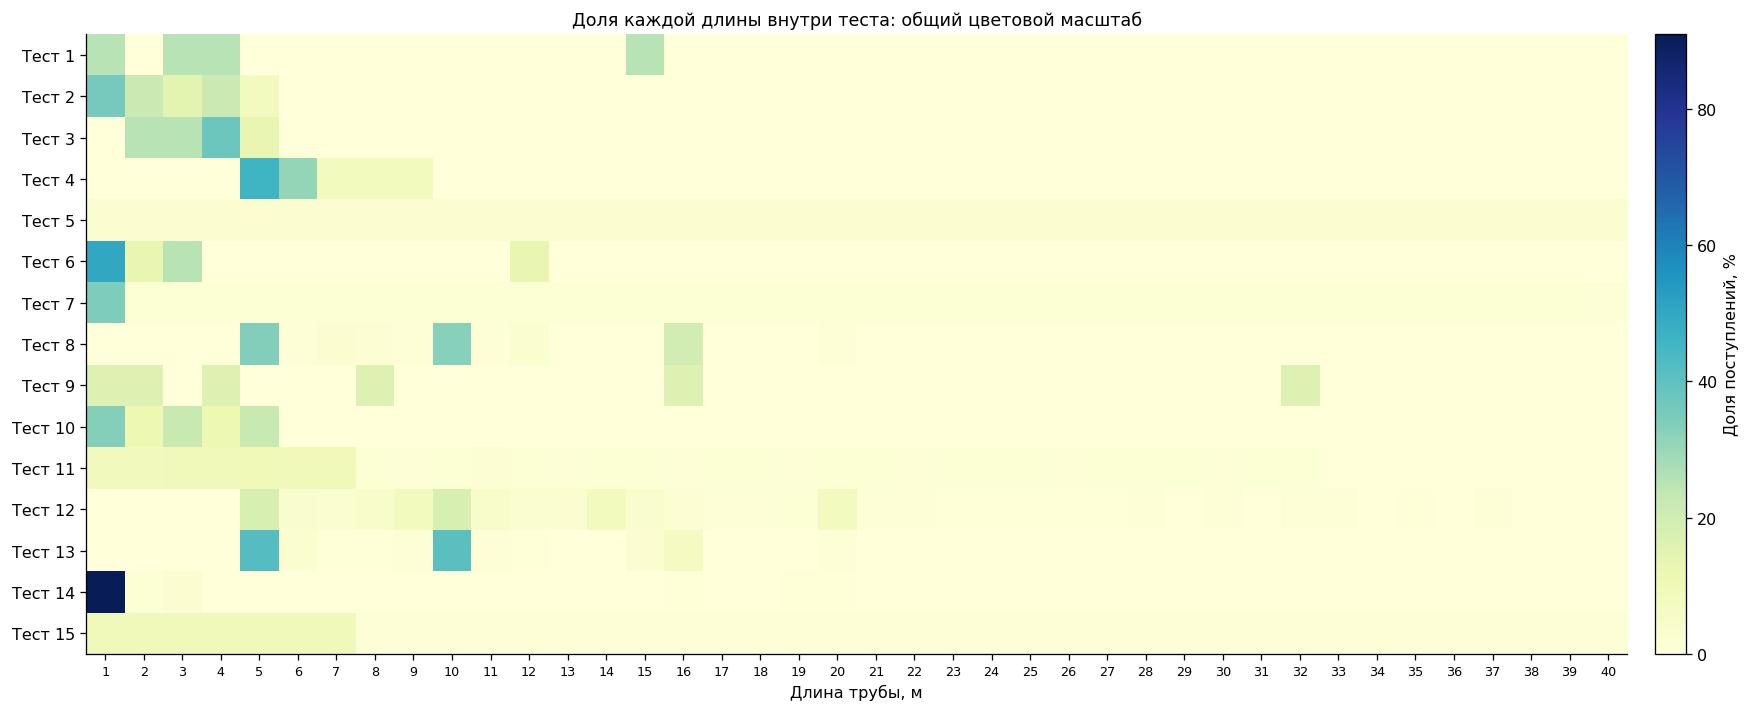

Полные таблицы: length_counts — количества; length_percent — проценты.


In [5]:
fig, ax = plt.subplots(figsize=(17, max(5, .42 * len(test_ids))))
im = ax.imshow(length_percent.to_numpy(), aspect="auto", interpolation="nearest", cmap="YlGnBu")
ax.set_xticks(np.arange(40), labels=lengths_axis, fontsize=8)
ax.set_yticks(np.arange(len(test_ids)), labels=[f"Тест {i}" for i in test_ids])
ax.set(xlabel="Длина трубы, м", title="Доля каждой длины внутри теста: общий цветовой масштаб")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Доля поступлений, %", pad=.015)
fig.tight_layout()
plt.show()

# Эти таблицы содержат все 40 длин во всех тестах; доступны для дальнейшего анализа.
assert np.allclose(length_percent.sum(axis=1), 100)
assert np.array_equal(length_counts.sum(axis=1).to_numpy(), summary["adds"].to_numpy())
print("Полные таблицы: length_counts — количества; length_percent — проценты.")

### Почему нельзя смотреть только на все трубы сразу

У объединённого распределения вес каждого теста пропорционален числу поступлений. В среднем распределении тестов каждый сценарий имеет одинаковый вес. Это **два разных описания данных**. Ни одно из них само по себе не оценивает распределение будущих закрытых тестов. Официальные веса баллов не являются вероятностями появления труб.

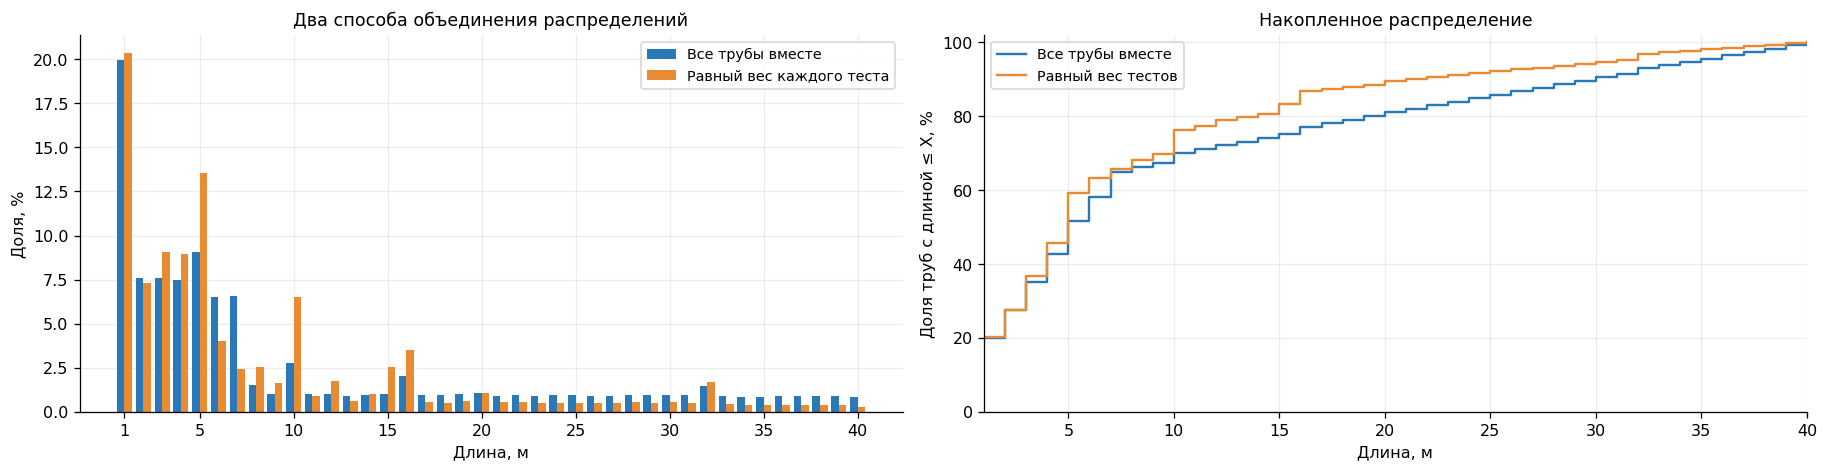

Тест **15** даёт **68.8%** всех поступлений. Поэтому общая гистограмма преимущественно описывает именно этот сценарий.

In [6]:
pooled_percent = length_counts.sum(axis=0) / len(pipes) * 100
equal_test_percent = length_percent.mean(axis=0)
largest_test = int(summary["adds"].idxmax())
largest_share = 100 * summary.at[largest_test, "adds"] / len(pipes)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
axes[0].bar(lengths_axis - .2, pooled_percent, width=.4, label="Все трубы вместе", color=BLUE)
axes[0].bar(lengths_axis + .2, equal_test_percent, width=.4, label="Равный вес каждого теста", color=ORANGE)
axes[0].set(xlabel="Длина, м", ylabel="Доля, %", title="Два способа объединения распределений")
axes[0].set_xticks([1, 5, 10, 15, 20, 25, 30, 35, 40])
axes[0].legend(fontsize=9)
axes[1].step(lengths_axis, pooled_percent.cumsum(), where="post", label="Все трубы вместе", color=BLUE)
axes[1].step(lengths_axis, equal_test_percent.cumsum(), where="post", label="Равный вес тестов", color=ORANGE)
axes[1].set(xlabel="Длина, м", ylabel="Доля труб с длиной ≤ X, %",
            title="Накопленное распределение", ylim=(0, 102), xlim=(1, 40))
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()
display(Markdown(f"Тест **{largest_test}** даёт **{largest_share:.1f}%** всех поступлений. "
                 "Поэтому общая гистограмма преимущественно описывает именно этот сценарий."))

## 4. Меняются ли поступления и удаления во времени?

Каждый сценарий разделён на 20 частей по **числу команд**, а не по физическому времени. Для каждой части считаем среднюю длину поступающих труб и долю команд удаления. В коротких тестах на часть может приходиться одна команда; серый цвет означает отсутствие данных для соответствующей метрики.

Если распределение меняется по ходу теста, статистика всего файла скрывает эти изменения. Это аргумент в пользу проверки скользящей статистики в алгоритме, но не доказательство её преимущества.

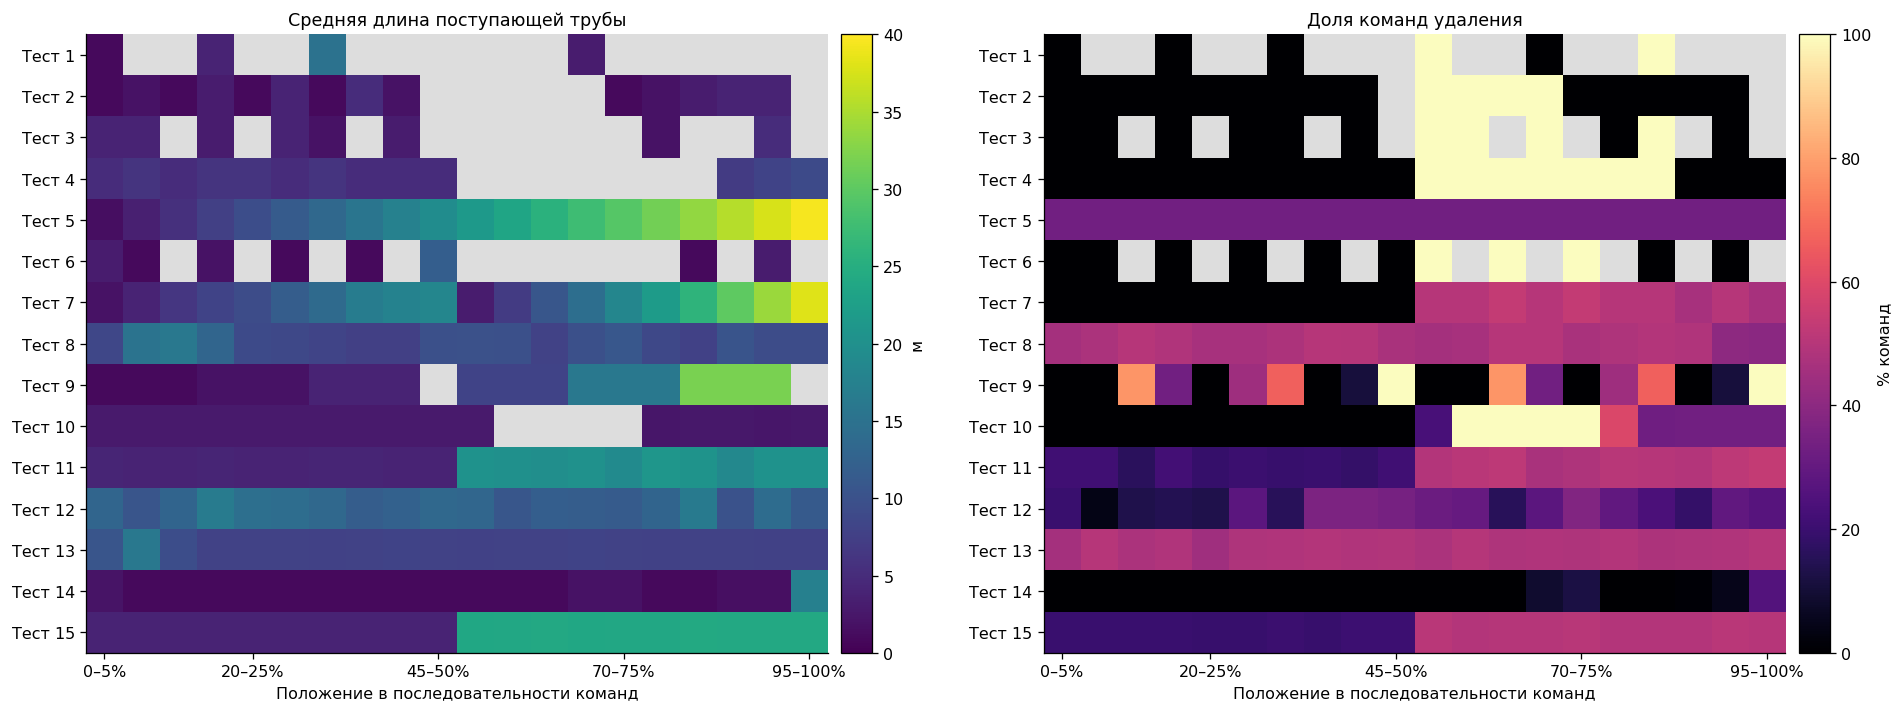

,Самая длинная серия укладок,Самая длинная серия удалений,Всего поступило метров / пик активных метров
test,,,
1,3,1,1.150
2,9,4,1.700
3,6,3,1.350
4,10,7,1.440
5,125,63,1.920
6,6,3,1.200
7,156,2,1.950
8,67,1,7.350
9,1000,500,1.330


**Первая и вторая половины по числу команд.** Расстояние TV лежит от 0 (одинаковые эмпирические распределения длин) до 1 (ни одной общей длины). Это описательная метрика, не проверка статистической значимости; на маленьких выборках она нестабильна.

,Поступлений в 1-й половине,Поступлений во 2-й половине,"Средняя в 1-й, м","Средняя во 2-й, м","1–2 м в 1-й, %","1–2 м во 2-й, %",TV между половинами
test,,,,,,,
1,3,1,6.667,3.000,33.333,0.000,1.000
2,9,5,2.222,2.800,66.667,40.000,0.378
3,6,2,3.333,3.500,16.667,50.000,0.833
4,10,3,5.400,8.000,0.000,0.000,1.000
5,2500,2500,10.500,30.500,10.000,0.000,1.000
6,5,3,1.600,5.333,80.000,33.333,0.467
7,156,78,10.750,20.500,51.923,3.846,0.494
8,1705,1753,10.318,9.373,0.000,0.000,0.178
9,3000,3000,2.333,18.667,66.667,0.000,1.000


In [7]:
phase = events[["test", "step", "is_add", "pipe_length"]].copy()
scenario_sizes = phase["test"].map(summary["commands"]).to_numpy()
phase["bin"] = np.minimum((phase["step"].to_numpy() - 1) * TIME_BINS // scenario_sizes, TIME_BINS - 1)
mean_by_phase = phase.loc[phase["is_add"]].pivot_table(
    index="test", columns="bin", values="pipe_length", aggfunc="mean").reindex(
    index=test_ids, columns=range(TIME_BINS))
remove_by_phase = (phase.assign(is_remove=~phase["is_add"]).pivot_table(
    index="test", columns="bin", values="is_remove", aggfunc="mean").reindex(
    index=test_ids, columns=range(TIME_BINS)) * 100)
small_by_phase = (phase.loc[phase["is_add"]].assign(is_small=lambda x: x["pipe_length"] <= 2)
    .pivot_table(index="test", columns="bin", values="is_small", aggfunc="mean")
    .reindex(index=test_ids, columns=range(TIME_BINS)) * 100)

fig, axes = plt.subplots(1, 2, figsize=(17, max(5, len(test_ids) * .42)))
for ax, matrix, title, cmap_name, vmax, color_label in [
    (axes[0], mean_by_phase, "Средняя длина поступающей трубы", "viridis", 40, "м"),
    (axes[1], remove_by_phase, "Доля команд удаления", "magma", 100, "% команд"),
]:
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad("#dddddd")
    im = ax.imshow(matrix.to_numpy(), aspect="auto", interpolation="nearest", cmap=cmap, vmin=0, vmax=vmax)
    ax.set_yticks(range(len(test_ids)), labels=[f"Тест {i}" for i in test_ids])
    positions = np.linspace(0, TIME_BINS - 1, 5).astype(int)
    ax.set_xticks(positions, labels=[f"{100 * b / TIME_BINS:.0f}–{100 * (b + 1) / TIME_BINS:.0f}%" for b in positions])
    ax.set(title=title, xlabel="Положение в последовательности команд")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label=color_label, pad=.015)
fig.tight_layout()
plt.show()

run_columns = {"longest_add_run": "Самая длинная серия укладок", "longest_remove_run": "Самая длинная серия удалений",
               "inserted_to_peak": "Всего поступило метров / пик активных метров"}
display(summary[list(run_columns)].rename(columns=run_columns).round(2))

# Сравнение двух половин по номеру команды: порядок поступлений может быть важнее общей гистограммы.
drift_rows = []
for test_id in test_ids:
    arrivals = events.loc[(events["test"] == test_id) & events["is_add"]]
    split_step = summary.at[test_id, "commands"] // 2
    first = arrivals.loc[arrivals["step"] <= split_step, "pipe_length"].to_numpy()
    second = arrivals.loc[arrivals["step"] > split_step, "pipe_length"].to_numpy()
    if len(first) and len(second):
        p_first = np.bincount(first, minlength=41)[1:41] / len(first)
        p_second = np.bincount(second, minlength=41)[1:41] / len(second)
        tv = float(np.abs(p_first - p_second).sum() / 2)
    else:
        tv = np.nan
    drift_rows.append({
        "test": test_id, "first_count": len(first), "second_count": len(second),
        "first_mean": float(first.mean()) if len(first) else np.nan,
        "second_mean": float(second.mean()) if len(second) else np.nan,
        "first_small_pct": 100 * float((first <= 2).mean()) if len(first) else np.nan,
        "second_small_pct": 100 * float((second <= 2).mean()) if len(second) else np.nan,
        "tv_distance": tv,
    })
drift_summary = pd.DataFrame(drift_rows).set_index("test")
display(Markdown("**Первая и вторая половины по числу команд.** Расстояние TV лежит от 0 "
                 "(одинаковые эмпирические распределения длин) до 1 (ни одной общей длины). "
                 "Это описательная метрика, не проверка статистической значимости; "
                 "на маленьких выборках она нестабильна."))
display(drift_summary.rename(columns={
    "first_count": "Поступлений в 1-й половине", "second_count": "Поступлений во 2-й половине",
    "first_mean": "Средняя в 1-й, м", "second_mean": "Средняя во 2-й, м",
    "first_small_pct": "1–2 м в 1-й, %", "second_small_pct": "1–2 м во 2-й, %",
    "tv_distance": "TV между половинами",
}).round(3))

## 5. Активная нагрузка и верхняя граница KPI

Активная длина — сумма длин труб, которые к данному шагу поступили и ещё не удалены. Она полностью определяется входными данными и не зависит от размещения.

Траншея должна вместить пиковую активную длину и увеличивается только участками по 20 м. Поэтому:

$$
T_{\min} = 20\left\lceil \frac{\max_t A_t}{20}\right\rceil,
\qquad KPI \leq \frac{A_{\mathrm{final}}}{T_{\min}}.
$$

`A_t` — активная длина после команды `t`. Это **нижняя граница требуемой длины траншеи и верхняя граница KPI**, а не гарантированно достижимый оптимум: фрагментация и неизвестные будущие команды могут потребовать дополнительной траншеи. Уменьшать уже выкопанную траншею по протоколу нельзя.

Если перед завершением удаляется много труб, KPI может быть низким даже при идеальной упаковке. Результат реального алгоритма полезно сравнивать и с этой границей, и с другими алгоритмами на том же тесте.

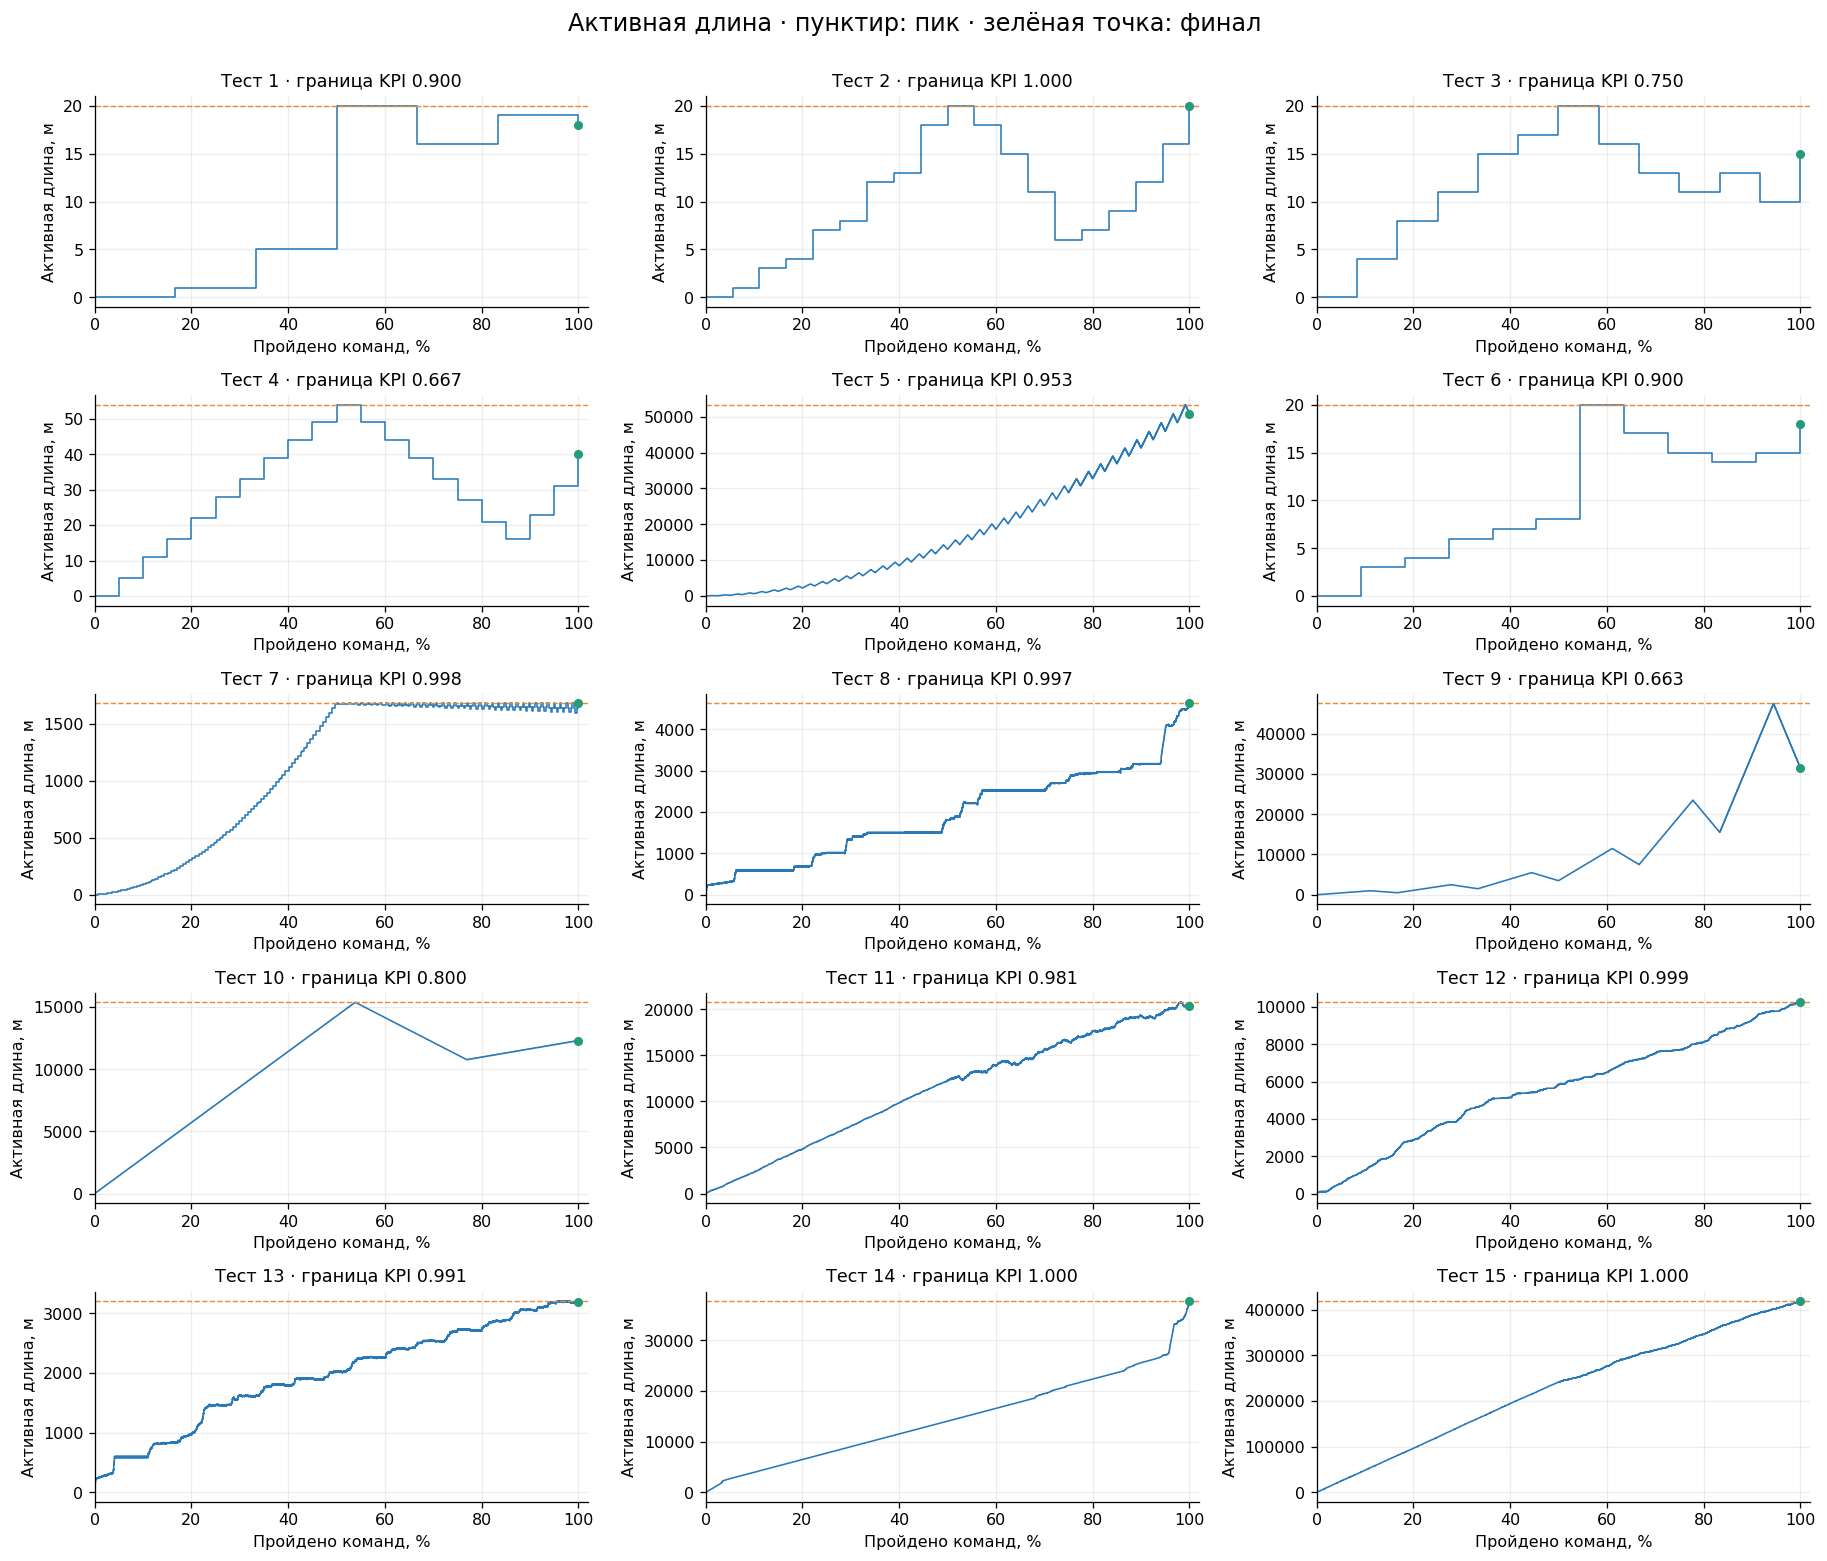

,Вес,"Пик длины, м","Финальная длина, м",Пик числа труб,Труб в финале,"Нижняя граница траншеи, м",Верхняя граница KPI,Верхняя граница балла
test,,,,,,,,
1,0.100,20,18,3,2,20,0.900,0.090
2,1.000,20,20,10,10,20,1.000,1.000
3,1.000,20,15,6,4,20,0.750,0.750
4,1.000,54,40,10,6,60,0.667,0.667
5,1.000,53360,50840,2543,2480,53360,0.953,0.953
6,1.000,20,18,6,5,20,0.900,0.900
7,1.000,1677,1677,156,156,1680,0.998,0.998
8,1.000,4627,4627,351,351,4640,0.997,0.997
9,1.000,47500,31500,3500,3000,47500,0.663,0.663


**Сумма весов открытых тестов:** 32.1. **Суммарная верхняя граница балла на них:** 30.7575. Это не полученный результат решения и не итог соревнования: закрытые тесты здесь отсутствуют.

In [8]:
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.7 * nrows), squeeze=False)
for ax, test_id in zip(axes.flat, test_ids):
    group = events.loc[events["test"] == test_id]
    x = np.r_[0, group["step"].to_numpy()] / summary.at[test_id, "commands"] * 100
    y = np.r_[0, group["live_m"].to_numpy()]
    ax.step(x, y, where="post", color=BLUE, lw=1)
    ax.axhline(summary.at[test_id, "peak_live_m"], color=ORANGE, ls="--", lw=.9)
    ax.scatter([100], [summary.at[test_id, "final_live_m"]], s=22, color=GREEN, zorder=3)
    ax.set(title=f"Тест {test_id} · граница KPI {summary.at[test_id, 'kpi_upper_bound']:.3f}",
           xlabel="Пройдено команд, %", ylabel="Активная длина, м", xlim=(0, 102))
    ax.ticklabel_format(axis="y", style="plain")
for ax in axes.flat[len(test_ids):]:
    ax.set_visible(False)
fig.suptitle("Активная длина · пунктир: пик · зелёная точка: финал", fontsize=15, y=1.002)
fig.tight_layout()
plt.show()

capacity_columns = {"weight": "Вес", "peak_live_m": "Пик длины, м", "final_live_m": "Финальная длина, м",
                    "peak_live_pipes": "Пик числа труб", "final_live_pipes": "Труб в финале",
                    "min_trench_m": "Нижняя граница траншеи, м", "kpi_upper_bound": "Верхняя граница KPI",
                    "weighted_upper_bound": "Верхняя граница балла"}
display(summary[list(capacity_columns)].rename(columns=capacity_columns).round(4))
display(Markdown(f"**Сумма весов открытых тестов:** {summary['weight'].sum():.1f}. "
                 f"**Суммарная верхняя граница балла на них:** {summary['weighted_upper_bound'].sum():.4f}. "
                 "Это не полученный результат решения и не итог соревнования: закрытые тесты здесь отсутствуют."))

## 6. Время жизни труб и удаления

Время жизни измеряется количеством команд между поступлением и удалением. На графике оно делится на число команд теста, чтобы сравнивать сценарии разного размера. Например, значение 0,1 означает интервал в 10% длины сценария.

**Коробчатая диаграмма включает только удалённые трубы.** Медиана — линия внутри коробки, коробка — P25–P75, усы — крайние наблюдения в пределах 1,5 межквартильного размаха. Отдельные выбросы скрыты, но остаются в расчёте P90 в таблице. Трубы, оставшиеся в финале, имеют незавершённое время жизни: мы знаем лишь, сколько команд они уже прожили. Исключение этих труб создаёт смещение, поэтому график нельзя трактовать как ожидаемый срок жизни любой новой трубы.

Доля удалённых труб определённой длины также описывает только этот сценарий. Разные длины могли поступать в разные моменты и иметь разное время наблюдения; такая доля не является независимой вероятностью повреждения или прогнозом.

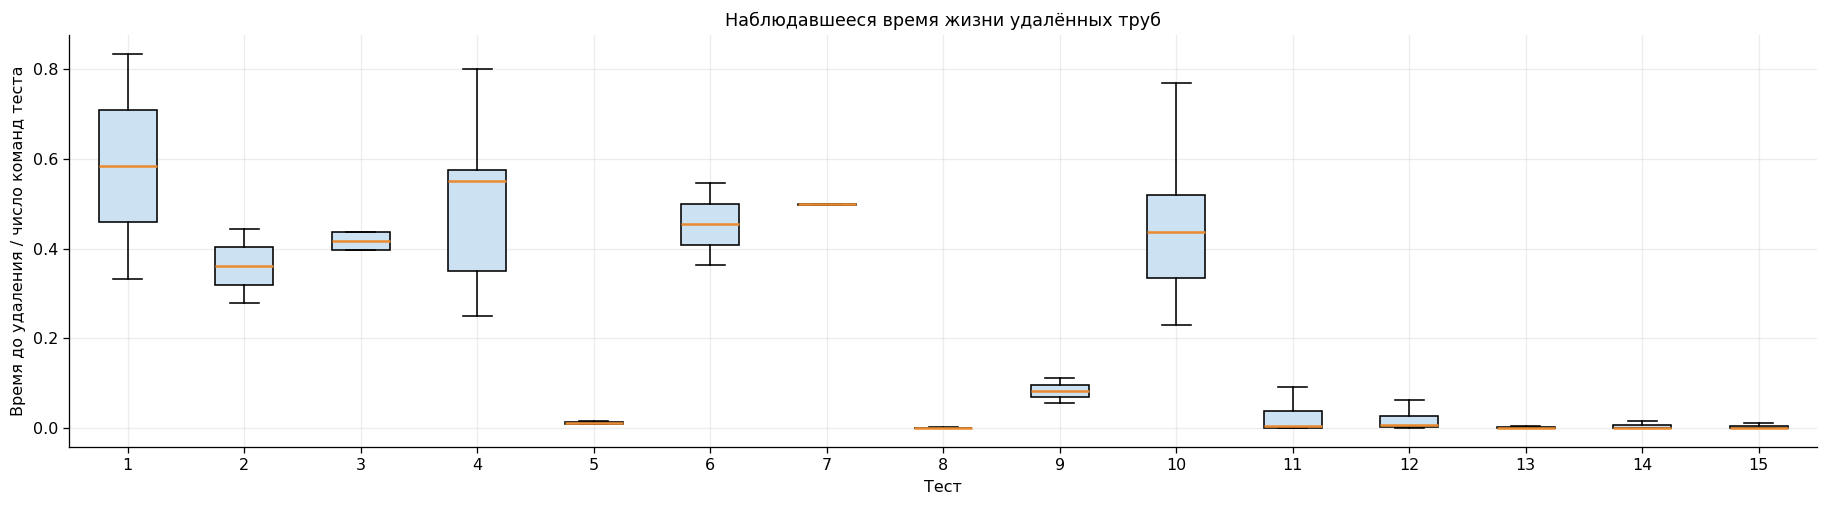

,Удалено труб,"Медиана жизни, команд","P90 жизни, команд",Медиана / число команд,Остались в финале,"Медиана возраста оставшихся, команд"
test,,,,,,
1,2,3.500,4.700,0.583,2,3.000
2,4,6.500,7.700,0.361,10,7.500
3,4,5.000,5.700,0.417,4,6.000
4,7,11.000,13.600,0.550,6,7.000
5,2520,94.000,119.000,0.012,2480,3 792.000
6,3,5.000,5.800,0.455,5,6.000
7,78,155.500,156.000,0.498,156,155.500
8,3107,3.000,13.000,0.000,351,1 629.000
9,3000,750.500,950.100,0.083,3000,4 750.000


In [9]:
removed_pipes = pipes.loc[pipes["removed"]].copy()
life_summary = removed_pipes.groupby("test").agg(
    removed_count=("pid", "size"),
    median_steps=("observed_steps", "median"),
    p90_steps=("observed_steps", lambda x: x.quantile(.9)),
    median_fraction=("observed_fraction", "median"),
).reindex(test_ids)
life_summary["survivors"] = summary["final_live_pipes"]
life_summary["survivor_median_observed_steps"] = (
    pipes.loc[~pipes["removed"]].groupby("test")["observed_steps"].median().reindex(test_ids))

available_ids = [i for i in test_ids if (removed_pipes["test"] == i).any()]
if available_ids:
    fig, ax = plt.subplots(figsize=(16, 4.5))
    box_data = [removed_pipes.loc[removed_pipes["test"] == i, "observed_fraction"].to_numpy()
                for i in available_ids]
    ax.boxplot(box_data, positions=np.arange(1, len(available_ids) + 1), showfliers=False,
               patch_artist=True, boxprops={"facecolor": "#cce2f3"},
               medianprops={"color": ORANGE, "linewidth": 1.6})
    ax.set_xticks(np.arange(1, len(available_ids) + 1), labels=[str(i) for i in available_ids])
    ax.set(xlabel="Тест", ylabel="Время до удаления / число команд теста",
           title="Наблюдавшееся время жизни удалённых труб")
    fig.tight_layout()
    plt.show()

display(life_summary.rename(columns={
    "removed_count": "Удалено труб", "median_steps": "Медиана жизни, команд",
    "p90_steps": "P90 жизни, команд", "median_fraction": "Медиана / число команд",
    "survivors": "Остались в финале", "survivor_median_observed_steps": "Медиана возраста оставшихся, команд",
}).round(3))

## 7. Подробный разбор выбранного теста

Измените `DETAIL_TEST` в первой кодовой ячейке и выполните этот раздел повторно. Доступны все загруженные номера тестов.

Таблица содержит **все длины от 1 до 40 м**, включая отсутствующие. Количество наблюдений важно: доля удалений 100% для одной трубы существенно менее информативна, чем для тысяч. Пустая доля означает, что трубы такой длины не поступали.

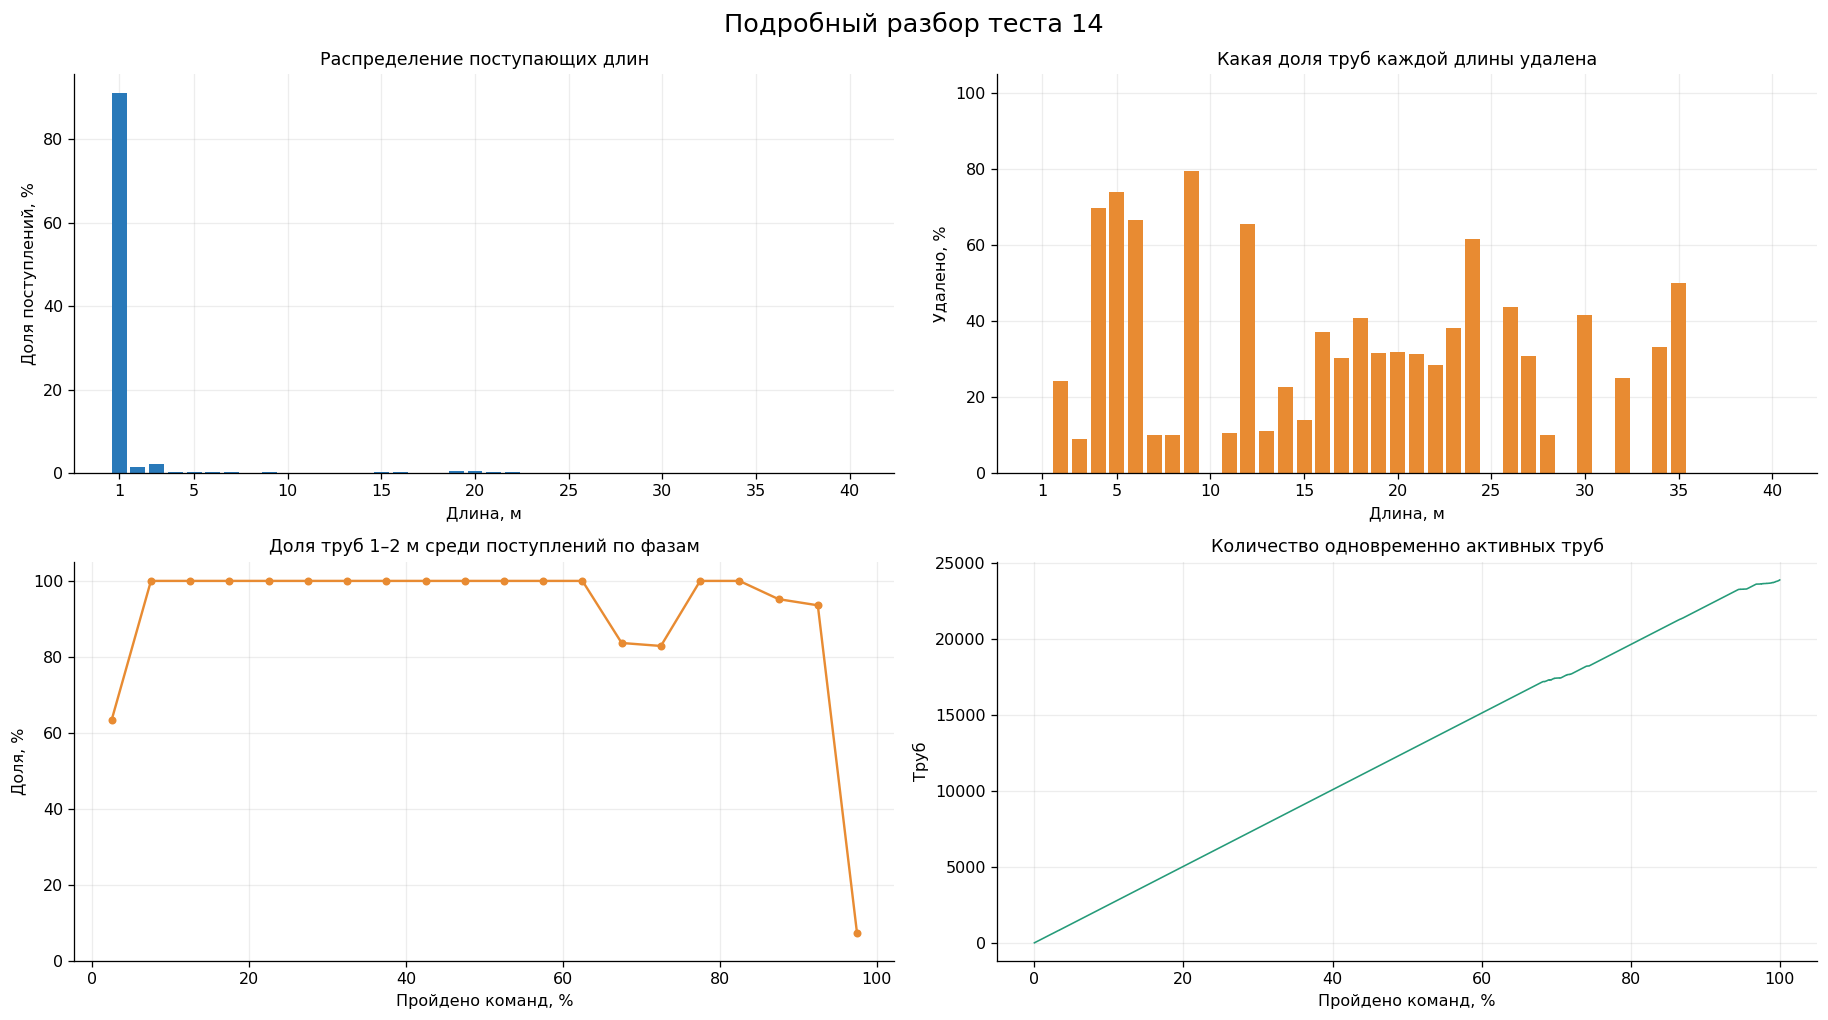

,Поступило труб,"Доля поступлений, %",Поступило метров,Удалено труб,Осталось труб,"Удалено, % от поступлений этой длины"
"Длина, м",,,,,,
1,22316,90.970,22316,16,22300,0.070
2,377,1.540,754,92,285,24.400
3,565,2.300,1695,51,514,9.030
4,83,0.340,332,58,25,69.880
5,77,0.310,385,57,20,74.030
6,60,0.240,360,40,20,66.670
7,50,0.200,350,5,45,10.000
8,10,0.040,80,1,9,10.000
9,68,0.280,612,54,14,79.410


In [10]:
if DETAIL_TEST not in test_ids:
    raise ValueError(f"Выберите DETAIL_TEST из {test_ids}")
detail_pipes = pipes.loc[pipes["test"] == DETAIL_TEST]
detail_events = events.loc[events["test"] == DETAIL_TEST]
removed_counts = (detail_pipes.loc[detail_pipes["removed"], "length"].value_counts()
                  .reindex(lengths_axis, fill_value=0))
detail_table = pd.DataFrame(index=pd.Index(lengths_axis, name="Длина, м"))
detail_table["Поступило труб"] = length_counts.loc[DETAIL_TEST].to_numpy()
detail_table["Доля поступлений, %"] = length_percent.loc[DETAIL_TEST].to_numpy()
detail_table["Поступило метров"] = detail_table.index.to_numpy() * detail_table["Поступило труб"]
detail_table["Удалено труб"] = removed_counts.to_numpy()
detail_table["Осталось труб"] = detail_table["Поступило труб"] - detail_table["Удалено труб"]
detail_table["Удалено, % от поступлений этой длины"] = (
    detail_table["Удалено труб"] / detail_table["Поступило труб"].replace(0, np.nan) * 100)

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
axes[0, 0].bar(lengths_axis, detail_table["Доля поступлений, %"], color=BLUE)
axes[0, 0].set(title="Распределение поступающих длин", xlabel="Длина, м", ylabel="Доля поступлений, %")
axes[0, 1].bar(lengths_axis, detail_table["Удалено, % от поступлений этой длины"], color=ORANGE)
axes[0, 1].set(title="Какая доля труб каждой длины удалена", xlabel="Длина, м", ylabel="Удалено, %", ylim=(0, 105))
phase_x = (np.arange(TIME_BINS) + .5) / TIME_BINS * 100
axes[1, 0].plot(phase_x, small_by_phase.loc[DETAIL_TEST], marker="o", ms=4, color=ORANGE)
axes[1, 0].set(title="Доля труб 1–2 м среди поступлений по фазам", xlabel="Пройдено команд, %", ylabel="Доля, %", ylim=(0, 105))
x = detail_events["step"].to_numpy() / summary.at[DETAIL_TEST, "commands"] * 100
axes[1, 1].step(x, detail_events["live_count"], where="post", color=GREEN, lw=1)
axes[1, 1].set(title="Количество одновременно активных труб", xlabel="Пройдено команд, %", ylabel="Труб")
for ax in axes[0]:
    ax.set_xticks([1, 5, 10, 15, 20, 25, 30, 35, 40])
fig.suptitle(f"Подробный разбор теста {DETAIL_TEST}", fontsize=16)
fig.tight_layout()
plt.show()
display(detail_table.round(2))

## 8. Выводы для выбора алгоритма

Ниже факты вычисляются из загруженных файлов. Они помогают сформулировать гипотезы, но не заменяют сравнение стратегий на интеракторе.

In [11]:
most_small = int(summary["small_1_2_pct"].idxmax())
least_bound = int(summary["kpi_upper_bound"].idxmin())
most_deletions = int(summary["removal_event_pct"].idxmax())
no_small = summary.index[summary["small_1_2_pct"] == 0].tolist()
most_diverse = int(summary["entropy_bits"].idxmax())

display(Markdown(f"""
- **Универсальный штраф за остатки 1–2 м требует проверки.** В тесте **{most_small}** трубы такой длины составляют **{summary.at[most_small, 'small_1_2_pct']:.2f}%** поступлений. Они могут быть полезны для заполнения мелких промежутков. В тестах **{', '.join(map(str, no_small)) or '—'}** трубы 1–2 м отсутствуют. При этом частота малых труб сама по себе не доказывает, что они придут после образования промежутка.
- **Большой тест доминирует в общей статистике.** Тест **{largest_test}** содержит **{largest_share:.1f}%** всех поступивших труб; сравнивать стратегии нужно по каждому тесту и по взвешенной сумме баллов.
- **Длины меняются по ходу сценария.** В тесте **{largest_test}** средняя длина поступления в первой половине команд — **{drift_summary.at[largest_test, 'first_mean']:.2f} м**, во второй — **{drift_summary.at[largest_test, 'second_mean']:.2f} м**. Общая гистограмма скрывает эту разницу. Для онлайн-оценки полезности остатка стоит проверить адаптацию к недавним поступлениям.
- **Удаления существенны.** Максимальная доля команд удаления — **{summary.at[most_deletions, 'removal_event_pct']:.2f}%** в тесте **{most_deletions}**. Это аргумент в пользу эффективного объединения соседних свободных участков и поиска труб по PID.
- **KPI = 1 достижим не на каждом сценарии даже по грубой границе.** В тесте **{least_bound}** финальная активная длина равна **{int(summary.at[least_bound, 'final_live_m']):,} м**, а минимальная траншея по пику — **{int(summary.at[least_bound, 'min_trench_m']):,} м**. Значит KPI не может превышать **{summary.at[least_bound, 'kpi_upper_bound']:.4f}**, независимо от стратегии.
- **Разнообразие длин различается.** Самая высокая энтропия — **{summary.at[most_diverse, 'entropy_bits']:.3f} бит** в тесте **{most_diverse}**. Для редких длин и небольших тестов отдельные проценты следует читать вместе с числом наблюдений.
"""))


- **Универсальный штраф за остатки 1–2 м требует проверки.** В тесте **14** трубы такой длины составляют **92.51%** поступлений. Они могут быть полезны для заполнения мелких промежутков. В тестах **4, 8, 12** трубы 1–2 м отсутствуют. При этом частота малых труб сама по себе не доказывает, что они придут после образования промежутка.
- **Большой тест доминирует в общей статистике.** Тест **15** содержит **68.8%** всех поступивших труб; сравнивать стратегии нужно по каждому тесту и по взвешенной сумме баллов.
- **Длины меняются по ходу сценария.** В тесте **15** средняя длина поступления в первой половине команд — **4.00 м**, во второй — **24.05 м**. Общая гистограмма скрывает эту разницу. Для онлайн-оценки полезности остатка стоит проверить адаптацию к недавним поступлениям.
- **Удаления существенны.** Максимальная доля команд удаления — **48.41%** в тесте **13**. Это аргумент в пользу эффективного объединения соседних свободных участков и поиска труб по PID.
- **KPI = 1 достижим не на каждом сценарии даже по грубой границе.** В тесте **9** финальная активная длина равна **31,500 м**, а минимальная траншея по пику — **47,500 м**. Значит KPI не может превышать **0.6632**, независимо от стратегии.
- **Разнообразие длин различается.** Самая высокая энтропия — **5.322 бит** в тесте **5**. Для редких длин и небольших тестов отдельные проценты следует читать вместе с числом наблюдений.


### Какие эксперименты провести дальше

| Гипотеза | Что сравнить | Что измерять |
| --- | --- | --- |
| Best Fit полезен как исходная точка | Best Fit и укладка только в конец | KPI каждого теста, взвешенная сумма, время выполнения |
| Штраф за мелкие остатки зависит от сценария | Best Fit без штрафа и несколько фиксированных штрафов | Изменение балла по каждому тесту, а не только общий средний KPI |
| Локальная статистика полезнее общей | Оценка полезности остатка по всей наблюдавшейся истории и по скользящему окну | Балл, задержка адаптации, время и память |
| Слияние свободных промежутков критично при удалениях | Реализации с корректным объединением соседних промежутков и базовая реализация | Количество промежутков, размеры остатков, дополнительные метры траншеи |

**Для честной проверки:** выбрать часть открытых тестов для настройки и отдельную часть для проверки, не подбирать параметры по всей совокупности. Всего 15 сценариев, поэтому единичное разбиение даёт ограниченную уверенность; полезна проверка на нескольких разбиениях по целым сценариям. Деление отдельных труб одного теста случайным образом нарушает временную структуру.

Онлайн-алгоритм может использовать только уже полученные команды. Знание длины файла, будущих удалений, распределения всего конкретного теста, его номера или веса из заголовка не должно становиться входом алгоритма. Частоты в этом ноутбуке — инструмент исследования.

Если будет реализован симулятор размещения, стоит добавить распределение свободных промежутков, долю свободных метров в участках меньше очередной трубы, число расширений и отношение фактического KPI к рассчитанной верхней границе. Эти показатели нельзя получить только из входных файлов без выбора стратегии.